In [88]:
"""
Two-Neutron Separation Energies (S2n)
=======================================
Produces:
  - Figure A: S2n vs N for many isotopic chains (magic numbers)
  - Figure B: same, with deformed mid-shell regions marked (for arrows to deformation plot)
  - Figure C: Ca chain vs NN-only and NN+3N calculations (three-nucleon forces)

S2n is the energy needed to remove two neutrons:
    S2n(Z, N) = B(Z, N) - B(Z, N-2)
              = Delta(Z, N-2) - Delta(Z, N) + 2*Delta_n
where Delta is the mass excess and Delta_n = 8071.318 keV (neutron mass excess).

Data source: nubase2020.txt (NUBASE2020) [Kondev et al., Chinese Physics C 45,
030001 (2021)], from the IAEA Atomic Mass Data Center
(https://www-nds.iaea.org/amdc/). Place it alongside this notebook.
"""

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.patches import Rectangle, ConnectionPatch
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
import pandas as pd
import os

In [61]:
def parse_nubase(filepath):
    """Parses ground-state mass excesses from a NUBASE2020 ASCII file.

    AAA in cols 1-3, ZZZi in cols 5-8, mass excess (keV) in cols 19-31.
    A '#' in the mass field flags a systematics-derived (unmeasured) mass.
    """
    records = []
    with open(filepath, 'r', encoding='utf-8', errors='replace') as f:
        for line in f:
            if line.startswith('#') or not line.strip():
                continue

            A_str = line[0:3].strip()
            ZZZi = line[4:8]
            Z_str = ZZZi[0:3].strip()
            isomer_flag = ZZZi[3:4].strip()
            mass_excess_field = line[18:31]

            if not A_str or not Z_str or isomer_flag != '0':
                continue  # ground states only

            try:
                A, Z = int(A_str), int(Z_str)
                mass_excess = float(mass_excess_field.replace('#', '').strip())
            except ValueError:
                continue

            records.append({
                'A': A,
                'Z': Z,
                'N': A - Z,
                'mass_excess': mass_excess,              # keV
                'predicted': '#' in mass_excess_field,   # not measured
            })
    return pd.DataFrame(records)


df = parse_nubase('nubase2020.txt')
df = df[~df.predicted]   # keep measured masses only
print(f"Ground-state nuclides with measured masses: {len(df)}")

Ground-state nuclides with measured masses: 2550


In [62]:
"""
Compute S2n
-----------
Shift each isotopic chain by two neutrons and merge, so each row has
Delta(Z, N) and Delta(Z, N-2) side by side.
"""

DELTA_N = 8071.318 # keV, mass excess of neutron

prev = df[['Z', 'N', 'mass_excess']].copy()
prev['N'] = prev['N'] + 2 

s2n = df.merge(prev, on=['Z', 'N'], suffixes=('', '_prev'))
s2n['S2n'] = (s2n['mass_excess_prev'] - s2n['mass_excess'] + 2 * DELTA_N) / 1000  # keV to MeV
s2n = s2n.sort_values(by=['Z', 'N'])

# Quick check: 48Ca -> 50Ca should drop by ~6 MeV (N = 28 shell closure)
print(s2n[(s2n['Z'] == 20) & (s2n.N % 2 == 0)][['N', 'S2n']].to_string(index=False))

 N       S2n
18 31.751136
20 28.930538
22 19.843524
24 19.064046
26 17.813536
28 17.227904
30 11.506968
32 10.819736
34  7.036336
36  4.492636


In [63]:
"""
Plot settings (shared by all figures)
-------------------------------------
"""

Z_MIN, Z_MAX = 8, 92
Z_STEP = 2            # 1 = every element, 2 = even Z only, 4 = every 4th ... fewer, clearer lines
EVEN_N_ONLY = True    # odd-N points make chains zig-zag into their neighbours
magic_numbers = [8, 20, 28, 50, 82, 126]
line_color = 'black'


def plot_chains(ax, data, color=line_color, lw=0.6):
    """One line per element. Lines break where a chain has missing nuclei."""
    for Z, chain in data.groupby('Z'):
        if not (Z_MIN <= Z <= Z_MAX) or Z % Z_STEP != 0:
            continue
        if EVEN_N_ONLY:
            chain = chain[chain.N % 2 == 0]
        step = 2 if EVEN_N_ONLY else 1
        segment = (chain.N.diff() > step).cumsum()   # new segment at each gap
        for _, seg in chain.groupby(segment):
            ax.plot(seg.N, seg.S2n, color=color, lw=lw)


def mark_magic(ax, numbers, label=True):
    for n in numbers:
        ax.axvline(n, color='orange', linestyle=':', linewidth=1, zorder=0)
        if label:
            ax.text(n, ax.get_ylim()[1], f'$N={n}$', ha='center', va='bottom',
                    color='darkorange', fontsize=11)

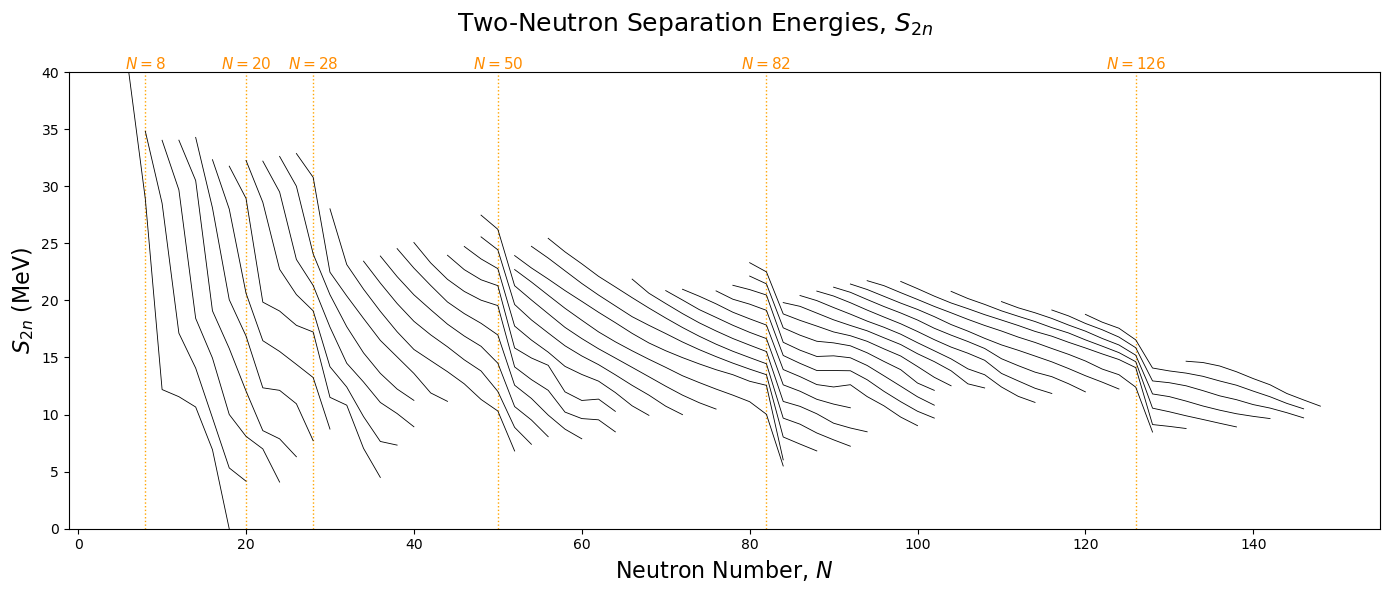

In [87]:
"""
Figure A: S2n overview
----------------------
Sharp drops just after each magic number = shell closures.
"""

fig, ax = plt.subplots(figsize=(14, 6))
fig.suptitle('Two-Neutron Separation Energies, $S_{2n}$', fontsize=18, y=0.98)
plot_chains(ax, s2n)
ax.set_ylim(0, 40)
mark_magic(ax, magic_numbers)

ax.set_xlabel('Neutron Number, $N$', fontsize=16)
ax.set_ylabel('$S_{2n}$ (MeV)', fontsize=16)
plt.tight_layout()
plt.savefig('s2nPlots/s2n_overview.png', dpi=200)
plt.show()

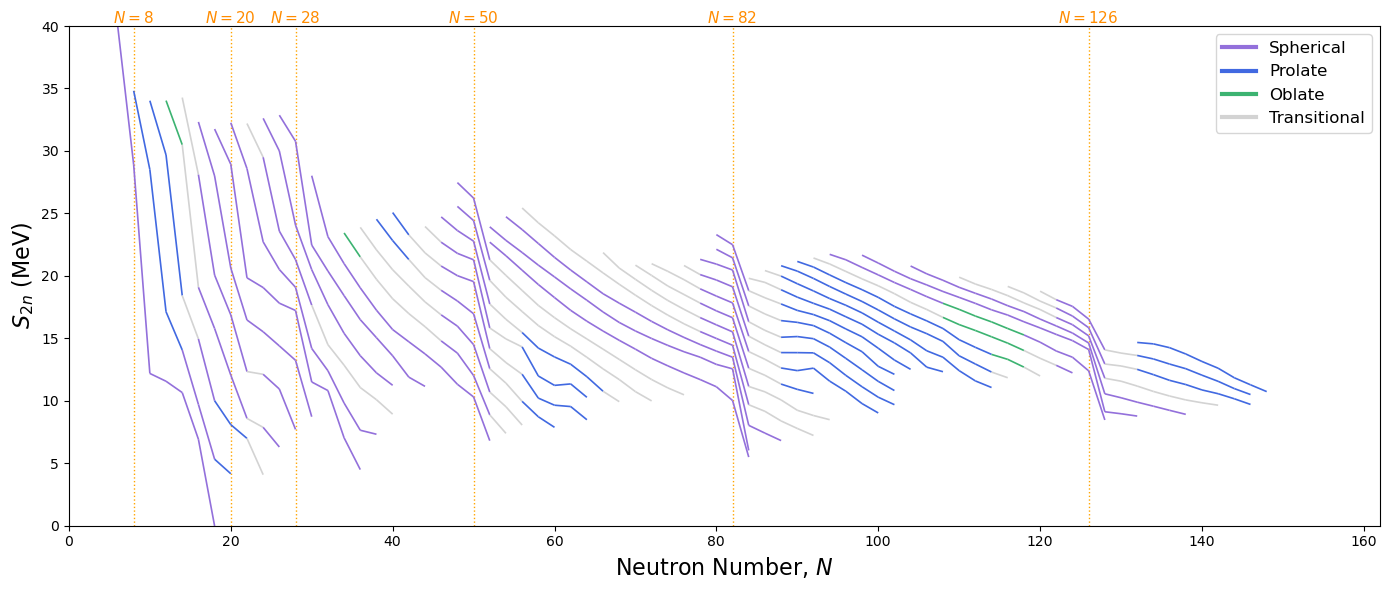

In [91]:
"""
Figure B: S2n coloured by nuclear shape
---------------------------------------
Shape depends on BOTH Z and N, so each nucleus is classified by where it sits on
the nuclear chart (e.g. N=20 is spherical for Ca but deformed for Ne/Na/Mg, the
'island of inversion').

Shape regions are boxes in (Z, N), read off the deformation chart shown on the
next slide. They are approximate: edit the boxes so they match your image.
Rules, in order:
  1. inside a box in `shape_regions`  -> that shape
  2. Z or N within 2 of a magic number -> spherical
  3. anything else                     -> transitional (grey)
"""

shape_colors = {
    'Spherical':    'mediumpurple',
    'Prolate':      'royalblue',
    'Oblate':       'mediumseagreen',
    'Transitional': 'lightgrey',
}

shape_regions = [          # (shape, Z_min, Z_max, N_min, N_max)   approximate
    ('Prolate', 10, 12, 10, 14),     # 20Ne, 24Mg region
    ('Prolate', 10, 12, 19, 22),     # island of inversion: 30Ne, 31Na, 32Mg
    ('Oblate',  14, 14, 14, 14),     # 28Si
    ('Oblate',  32, 36, 34, 36),     # 68Se, 72Kr region
    ('Prolate', 36, 40, 38, 42),     # A ~ 80 (Kr, Sr, Zr)
    ('Prolate', 36, 42, 58, 66),     # Sr/Zr, sudden onset at N = 60
    ('Prolate', 58, 76, 90, 114),    # rare earths
    ('Oblate',  76, 80, 110, 118),   # Os/Pt/Hg
    ('Prolate', 88, 100, 134, 152),  # actinides
]
SPHERICAL_WIDTH = 2                  # how close to a magic number counts as spherical
magic_Z = [8, 20, 28, 50, 82]


def classify(Z, N):
    for shape, z0, z1, n0, n1 in shape_regions:
        if z0 <= Z <= z1 and n0 <= N <= n1:
            return shape
    near_magic = (min(abs(N - m) for m in magic_numbers) <= SPHERICAL_WIDTH or
                  min(abs(Z - m) for m in magic_Z) <= SPHERICAL_WIDTH)
    return 'Spherical' if near_magic else 'Transitional'


shaped = s2n.copy()
shaped['shape'] = [classify(Z, N) for Z, N in zip(shaped.Z, shaped.N)]

fig, ax = plt.subplots(figsize=(14, 6))

for Z, chain in shaped.groupby('Z'):
    if not (Z_MIN <= Z <= Z_MAX) or Z % Z_STEP != 0:
        continue
    if EVEN_N_ONLY:
        chain = chain[chain.N % 2 == 0]
    step = 2 if EVEN_N_ONLY else 1
    chain = chain.sort_values('N')

    # one short segment per pair of neighbours, coloured by the heavier nucleus
    pts = chain[['N', 'S2n']].to_numpy()
    segs, cols = [], []
    for (n0, s0), (n1, s1), shape in zip(pts[:-1], pts[1:], chain['shape'].iloc[1:]):
        if n1 - n0 > step:           # gap in the chain: don't join
            continue
        segs.append([(n0, s0), (n1, s1)])
        cols.append(shape_colors[shape])
    ax.add_collection(LineCollection(segs, colors=cols, linewidths=1.2))

ax.set_xlim(0, shaped.N.max() + 4)
ax.set_ylim(0, 40)
mark_magic(ax, magic_numbers)

handles = [Line2D([], [], color=c, lw=3, label=s) for s, c in shape_colors.items()]
ax.legend(handles=handles, loc='upper right', fontsize=12)

ax.set_xlabel('Neutron Number, $N$', fontsize=16)
ax.set_ylabel('$S_{2n}$ (MeV)', fontsize=16)
plt.tight_layout()
plt.savefig('s2nPlots/s2n_deformation.png', dpi=200)
plt.show()

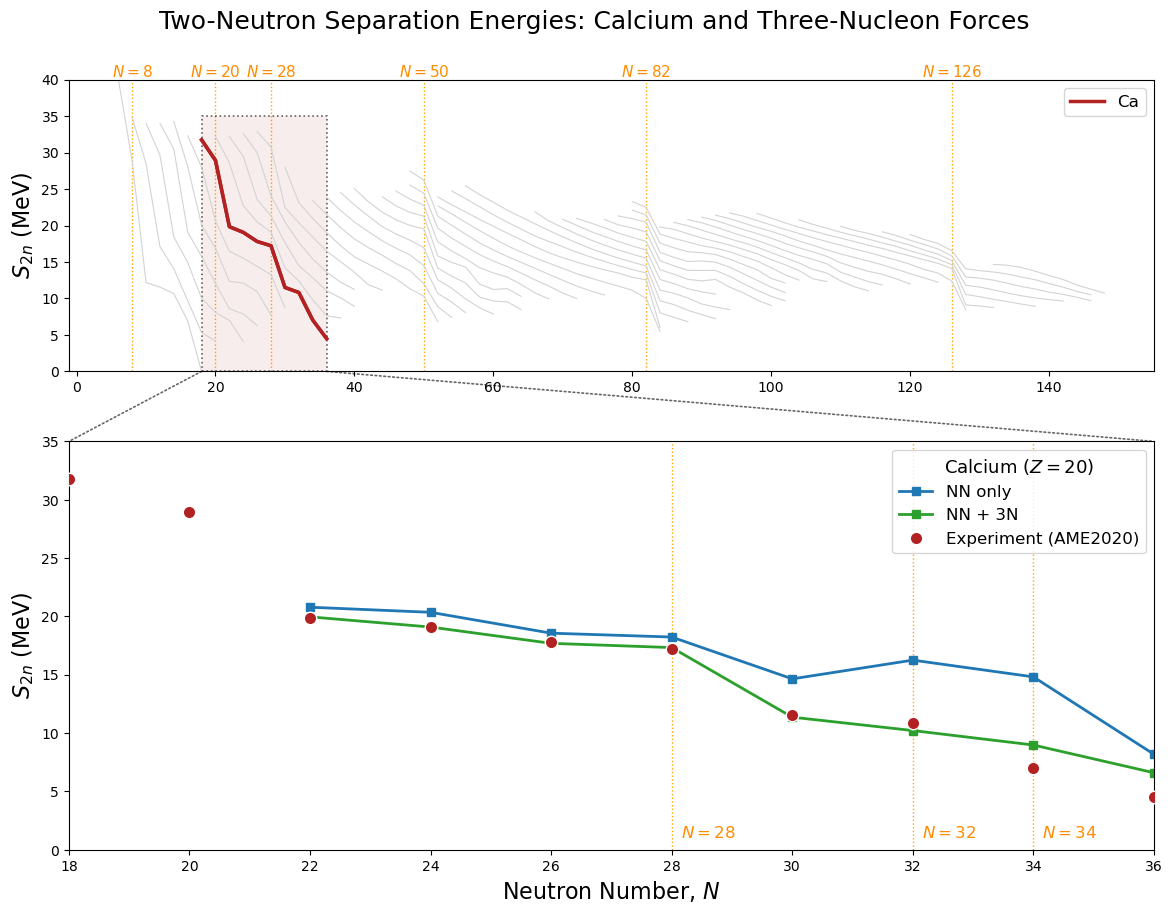

In [94]:
"""
Figure C: Calcium chain and three-nucleon forces
------------------------------------------------
Top: all chains in grey, Ca highlighted.
Bottom: Ca experiment vs NN-only (left) and vs NN + 3N (right).

Theory: Holt et al., J. Phys. G 39, 085111 (2012), Fig. 4(d), digitised with
WebPlotDigitizer as two columns (A, E): E = ground-state energy relative to 40Ca (MeV).
Converted here to S2n(N) = E(N-2) - E(N), with N = A - 20.
"""

import os

Z_FOCUS = 20                     # Ca
N_RANGE = (18, 36)
theory_files = {                 # label: (file, colour)
    'NN only': ('NNData/theory_NN.csv',   'tab:blue'),
    'NN + 3N': ('NNData/theory_NN3N.csv', 'tab:green'),
}


def load_theory(fname):
    """Read a WebPlotDigitizer (A, E) export and return a DataFrame with N, S2n."""
    raw = pd.read_csv(fname, header=None, names=['A', 'E'])
    raw = raw.apply(pd.to_numeric, errors='coerce').dropna()       # drop blank/header lines
    raw = pd.concat([pd.DataFrame({'A': [40.0], 'E': [0.0]}), raw])  # 40Ca is the zero
    raw = raw.sort_values('A')

    A_even = np.arange(40, int(raw.A.max()) + 1, 2)                # even-even Ca only
    th = pd.DataFrame({'N': A_even - Z_FOCUS,
                       'E': np.interp(A_even, raw.A, raw.E)})
    th['S2n'] = th.E.shift(1) - th.E                               # E(N-2) - E(N)
    return th.dropna()


ca = s2n[(s2n.Z == Z_FOCUS) & (s2n.N % 2 == 0)]
zoom = ca[(ca.N >= N_RANGE[0]) & (ca.N <= N_RANGE[1])]

S2N_ZOOM = (0, 35)               # y-range of the zoomed panel

fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(14, 10),
                                     gridspec_kw={'height_ratios': [1, 1.4], 'hspace': 0.2})

fig.suptitle('Two-Neutron Separation Energies: Calcium and Three-Nucleon Forces',
             fontsize=18, y=0.95)

# Top: context
plot_chains(ax_top, s2n, color='lightgrey', lw=0.8)
ax_top.plot(ca.N, ca.S2n, color='firebrick', lw=2.5,)
# box showing the region that is zoomed into below
ax_top.add_patch(Rectangle((N_RANGE[0], S2N_ZOOM[0]), N_RANGE[1] - N_RANGE[0],
                           S2N_ZOOM[1] - S2N_ZOOM[0], facecolor='firebrick', alpha=0.08,
                           edgecolor='none'))
ax_top.add_patch(Rectangle((N_RANGE[0], S2N_ZOOM[0]), N_RANGE[1] - N_RANGE[0],
                           S2N_ZOOM[1] - S2N_ZOOM[0], fill=False, edgecolor='black',
                           linestyle=':', alpha=0.6, linewidth=1.2))
ax_top.set_ylim(0, 40)
mark_magic(ax_top, magic_numbers)
ax_top.plot(ca.N, ca.S2n, color='firebrick', lw=2.5, label='Ca')
ax_top.legend(fontsize=12, loc='upper right')
ax_top.set_ylabel('$S_{2n}$ (MeV)', fontsize=16)

# Bottom: both theories and experiment on one panel
for label, (fname, colour) in theory_files.items():
    if os.path.exists(fname):
        th = load_theory(fname)
        th = th[(th.N >= N_RANGE[0]) & (th.N <= N_RANGE[1])]
        ax_bot.plot(th.N, th.S2n, color=colour, lw=2, marker='s', ms=6, label=label)
    else:
        print(f'{fname} not found, skipping "{label}"')

ax_bot.plot(zoom.N, zoom.S2n, 'o', color='firebrick', ms=9, mec='white',
            label='Experiment (AME2020)', zorder=5)
ax_bot.set_xlim(*N_RANGE)
ax_bot.set_ylim(0, 35)
mark_magic(ax_bot, [28, 32, 34], label=False)
for n in [28, 32, 34]:
    ax_bot.text(n + 0.15, 0.8, f'$N={n}$', ha='left', va='bottom',
                color='darkorange', fontsize=12)
ax_bot.set_xlabel('Neutron Number, $N$', fontsize=16)
ax_bot.set_ylabel('$S_{2n}$ (MeV)', fontsize=16)
ax_bot.legend(fontsize=12, loc='upper right', title='Calcium ($Z=20$)',
              title_fontsize=13)

# dotted lines from the bottom corners of the box to the top corners of the zoom panel
for n in N_RANGE:
    con = ConnectionPatch(xyA=(n, S2N_ZOOM[0]), coordsA=ax_top.transData,
                          xyB=(n, S2N_ZOOM[1]), coordsB=ax_bot.transData,
                          color='black', linestyle=':', alpha=0.6, linewidth=1.2)
    fig.add_artist(con)

plt.savefig('s2nPlots/s2n_calcium_3N.png', dpi=200, bbox_inches='tight')
plt.show()

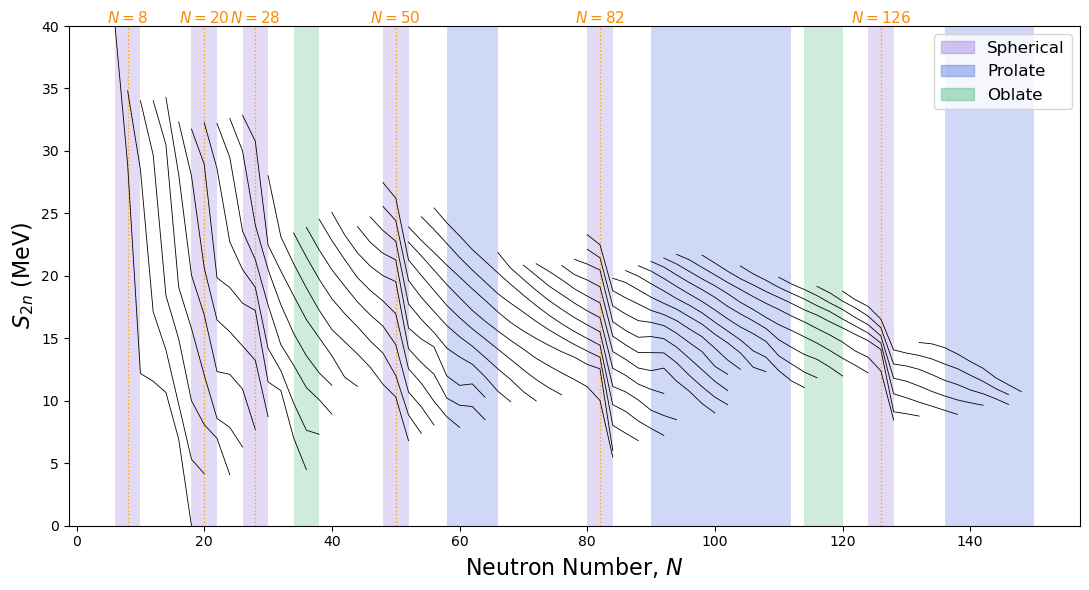

In [97]:
"""
Figure B: S2n with shape regions
--------------------------------
Shaded bands mark roughly where nuclei are spherical, prolate or oblate,
coloured to match the deformed-nucleus schematic on the slide.
Bands are approximate.
"""

from matplotlib.patches import Patch

shape_colors = {                       # change these to match your image exactly
    'Spherical': 'mediumpurple',
    'Prolate':   'royalblue',
    'Oblate':    'mediumseagreen',
}

shape_regions = {                      # (N_min, N_max) bands
    'Spherical': [(n - 2, n + 2) for n in magic_numbers],   # near shell closures
    'Prolate':   [(58, 66), (90, 112), (136, 150)],         # Sr/Zr, rare earths, actinides
    'Oblate':    [(34, 38), (114, 120)],                    # Se/Kr, Os/Pt/Hg
}

fig, ax = plt.subplots(figsize=(11, 6))

for shape, bands in shape_regions.items():
    for n_min, n_max in bands:
        ax.axvspan(n_min, n_max, color=shape_colors[shape], alpha=0.25, lw=0, zorder=0)

plot_chains(ax, s2n)
ax.set_ylim(0, 40)
mark_magic(ax, magic_numbers)

handles = [Patch(color=c, alpha=0.4, label=s) for s, c in shape_colors.items()]
ax.legend(handles=handles, loc='upper right', fontsize=12)

ax.set_xlabel('Neutron Number, $N$', fontsize=16)
ax.set_ylabel('$S_{2n}$ (MeV)', fontsize=16)
plt.tight_layout()
plt.savefig('s2nPlots/s2n_deformation.png', dpi=200)
plt.show()